## Data

### Pulling data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [3]:
df = yf.download('VND=X', start='2020-01-01', end='2026-08-31', multi_level_index=False)

[*********************100%***********************]  1 of 1 completed


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1733 entries, 2020-01-01 to 2026-08-28
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   1733 non-null   float64
 1   High    1733 non-null   float64
 2   Low     1733 non-null   float64
 3   Open    1733 non-null   float64
 4   Volume  1733 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 81.2 KB


In [5]:
df.head()

,Close,High,Low,Open,Volume
Date,,,,,
2020-01-01,23171.0,23171.0,23171.000000,23171.000000,0
2020-01-02,23171.0,23171.0,22805.605469,22835.800781,0
2020-01-03,23171.0,23171.0,22812.912109,23171.000000,0
2020-01-06,23171.0,23171.0,22744.150391,22744.150391,0
2020-01-07,23171.0,23171.0,22822.310547,23171.000000,0


In [6]:
df.describe()

,Close,High,Low,Open,Volume
count,1733.000000,1733.00000,1733.000000,1733.000000,1733.0
mean,24273.765196,24301.55045,24160.738838,24257.571027,0.0
std,1276.018934,1279.69549,1359.233706,1295.357381,0.0
min,22394.345703,22645.00000,22260.353516,22298.406250,0.0
25%,23174.000000,23176.00000,22841.644531,23130.000000,0.0
50%,23700.000000,23731.00000,23670.000000,23700.000000,0.0
75%,25440.000000,25453.00000,25420.000000,25440.000000,0.0
max,26425.000000,26449.00000,26399.000000,26425.000000,0.0


<Axes: xlabel='Date'>

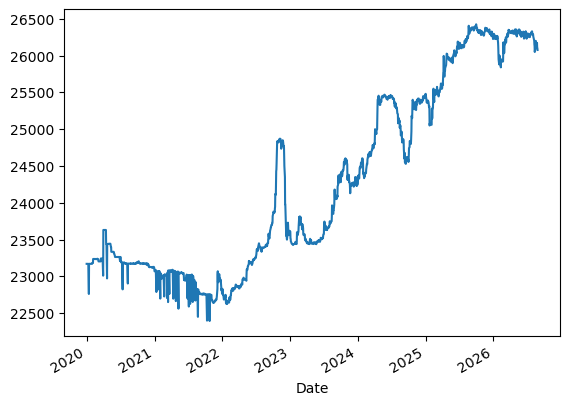

In [7]:
df.Close.plot()

In [8]:
df["Mid"] = (df["High"] + df["Low"])/2
df["Range"] = df["High"] - df["Low"]
df

,Close,High,Low,Open,Volume,Mid,Range
Date,,,,,,,
2020-01-01,23171.0,23171.0,23171.000000,23171.000000,0,23171.000000,0.000000
2020-01-02,23171.0,23171.0,22805.605469,22835.800781,0,22988.302734,365.394531
2020-01-03,23171.0,23171.0,22812.912109,23171.000000,0,22991.956055,358.087891
2020-01-06,23171.0,23171.0,22744.150391,22744.150391,0,22957.575195,426.849609
2020-01-07,23171.0,23171.0,22822.310547,23171.000000,0,22996.655273,348.689453
...,...,...,...,...,...,...,...
2026-08-24,26110.0,26187.0,26050.000000,26120.000000,0,26118.500000,137.000000
2026-08-25,26172.0,26177.0,26096.000000,26172.000000,0,26136.500000,81.000000
2026-08-26,26109.0,26114.0,26070.000000,26109.000000,0,26092.000000,44.000000


In [9]:
mid = df["Mid"]
rang = df["Range"]
mid.describe(), rang.describe()

(count     1733.000000
 mean     24231.144644
 std       1317.673913
 min      22473.052734
 25%      23003.171875
 50%      23705.000000
 75%      25438.000000
 max      26413.000000
 Name: Mid, dtype: float64,
 count    1733.000000
 mean      140.811612
 std       158.793792
 min         0.000000
 25%        34.000000
 50%        63.000000
 75%       323.691406
 max      2055.000000
 Name: Range, dtype: float64)

In [10]:
rang

Date
2020-01-01      0.000000
2020-01-02    365.394531
2020-01-03    358.087891
2020-01-06    426.849609
2020-01-07    348.689453
                 ...    
2026-08-24    137.000000
2026-08-25     81.000000
2026-08-26     44.000000
2026-08-27     28.000000
2026-08-28     58.000000
Name: Range, Length: 1733, dtype: float64

### Split the data

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
mid_train, mid_val_test = train_test_split(mid, test_size=0.3, shuffle=False)

In [13]:
mid_val, mid_test = train_test_split(mid_val_test, test_size=0.5, shuffle=False)

pd.concat([mid_train.describe(), mid_val.describe(), mid_test.describe()], axis=1, keys=["Train", "Val", "Test"])

,Train,Val,Test
count,1213.000000,260.000000,260.000000
mean,23509.876066,25558.321154,26268.963462
std,798.935160,487.452900,113.710368
min,22473.052734,24547.500000,25867.500000
25%,22915.460938,25339.375000,26255.875000
50%,23196.000000,25487.500000,26305.000000
75%,23900.000000,26002.250000,26332.500000
max,25468.000000,26397.500000,26413.000000


In [14]:
rang_train, rang_val_test = train_test_split(rang, test_size=0.3, shuffle=False)
rang_val, rang_test = train_test_split(rang_val_test, train_size=0.5, shuffle=False)

pd.concat([rang_train.describe(), rang_val.describe(), rang_test.describe()], axis=1, keys=["Train", "Val", "Test"])

,Train,Val,Test
count,1213.000000,260.000000,260.000000
mean,175.721784,64.803846,53.950000
std,177.100457,43.854665,29.088757
min,0.000000,0.000000,0.000000
25%,30.000000,38.000000,35.000000
50%,75.000000,57.500000,50.000000
75%,342.958984,80.000000,70.250000
max,2055.000000,310.000000,165.000000


### Scaling 

In [15]:
from sklearn.preprocessing import MinMaxScaler

In [16]:
scaler = MinMaxScaler(feature_range=(0, 1)).set_output(transform="pandas")

In [17]:
mid_train_scaled = scaler.fit_transform(mid_train.to_frame())
mid_val_scaled = scaler.fit_transform(mid_val.to_frame())
mid_test_scaled = scaler.fit_transform(mid_test.to_frame())

In [18]:
pd.concat([mid_train_scaled.describe(), mid_val_scaled.describe(), mid_test_scaled.describe()],
           axis=1, keys=["Train", "Val", "Test"])

,Train,Val,Test
,Mid,Mid,Mid
count,1213.000000,260.000000,260.000000
mean,0.346191,0.546390,0.735955
std,0.266761,0.263488,0.208452
min,0.000000,0.000000,0.000000
25%,0.147718,0.428041,0.711962
50%,0.241389,0.508108,0.802016
75%,0.476452,0.786351,0.852429
max,1.000000,1.000000,1.000000


In [19]:
rang_train_scaled = scaler.fit_transform(rang_train.to_frame())
rang_val_scaled = scaler.fit_transform(rang_val.to_frame())
rang_test_scaled = scaler.fit_transform(rang_test.to_frame())

In [20]:
pd.concat([rang_train_scaled.describe(), rang_val_scaled.describe(), rang_test_scaled.describe()],
           axis=1, keys=["Train", "Val", "Test"])

,Train,Val,Test
,Range,Range,Range
count,1213.000000,260.000000,260.000000
mean,0.085509,0.209045,0.326970
std,0.086180,0.141467,0.176295
min,0.000000,0.000000,0.000000
25%,0.014599,0.122581,0.212121
50%,0.036496,0.185484,0.303030
75%,0.166890,0.258065,0.425758
max,1.000000,1.000000,1.000000


### Export to csv

In [21]:
mid_train.to_csv("Midpoint_train.csv")

In [28]:
mid_val.to_csv("D:/KLTN/Week 1/Midpoint_val.csv")

In [25]:
mid_test.to_csv("D:/KLTN/Week 1/Midpoint_test.csv")

In [29]:
mid_train_scaled.to_csv("D:/KLTN/Week 1/Midpoint_train_scaled.csv")
mid_val_scaled.to_csv("D:/KLTN/Week 1/Midpoint_val_scaled.csv")
mid_test_scaled.to_csv("D:/KLTN/Week 1/Midpoint_test_scaled.csv")

In [30]:
rang_train.to_csv("D:/KLTN/Week 1/Range_train.csv")
rang_val.to_csv("D:/KLTN/Week 1/Range_val.csv")
rang_test.to_csv("D:/KLTN/Week 1/Rang_test.csv")

In [31]:
rang_train_scaled.to_csv("D:/KLTN/Week 1/Range_train_scaled.csv")
rang_val_scaled.to_csv("D:/KLTN/Week 1/Range_val_scaled.csv")
rang_test_scaled.to_csv("D:/KLTN/Week 1/Range_test_scaled.csv")

### Ways to scale data

| Tên Phương Pháp (Scaler) | Cơ chế biến đổi | Khi nào nên sử dụng |
| :--- | :--- | :--- |
| **StandardScaler** | Đưa dữ liệu về Trung bình (Mean) = 0, Độ lệch chuẩn (Std) = 1. | Là lựa chọn mặc định. Tốt cho các mô hình Hồi quy, SVM, KNN. |
| **MinMaxScaler** | Thu hẹp dữ liệu về một khoảng nhất định, thường là `[0, 1]`. | Dùng cho Neural Networks, xử lý ảnh (pixel), hoặc khi dữ liệu có giới hạn rõ ràng. |
| **RobustScaler** | Sử dụng Trung vị (Median) và Khoảng tứ phân vị (IQR). | Khi dữ liệu của bạn có chứa **nhiều nhiễu hoặc ngoại lai (outliers)** cực đoan. |
| **MaxAbsScaler** | Chia cho giá trị tuyệt đối lớn nhất, đưa về khoảng `[-1, 1]`. | Dùng cho **dữ liệu thưa thớt (Sparse data)** chứa rất nhiều số 0 (ví dụ: NLP, TF-IDF). |
| **PowerTransformer** | Áp dụng hàm mũ (Yeo-Johnson hoặc Box-Cox). | Khi cần ép dữ liệu bị lệch (skewed data) về dạng **phân phối chuẩn (Gaussian)**. |
| **QuantileTransformer**| Biến đổi phi tuyến tính dựa trên các điểm phân vị. | Khi phân phối dữ liệu gốc quá dị thường, không theo quy luật nào. |
| **Normalizer** | Chuẩn hóa theo **hàng** (từng mẫu dữ liệu) thay vì theo cột. | Phân loại văn bản (Text classification), tính toán độ tương đồng Cosine. |

## GRU